# Sketch-to-Image Generation with Stable Diffusion 1.5 and ControlNet

**Self-contained project implementation.** The notebook uses local sketches when provided; otherwise it creates three actual hand-drawn-style inputs from Google's Quick, Draw! public dataset (butterfly, camera, and house/building), then preprocesses them and runs Stable Diffusion 1.5 + ControlNet experiments.

Run from top to bottom in a GPU runtime (Kaggle: Settings → Accelerator → GPU). Internet access must be enabled for dataset/model downloads. The generated metrics are calculated from your run; this notebook does not contain fabricated results.

> Note: the automatic source is the Quick, Draw! dataset, not Google Images or Wikimedia book/image search. It contains individual human-drawn doodle strokes. The building input uses the dataset's `house` category as a simple building sketch. Source and dataset-license details are recorded in the attribution CSV.

## 1. Environment and reproducibility

The notebook fixes random seeds, records model/runtime settings, and, when no local sketches are supplied, downloads individual drawings from Google's Quick, Draw! dataset for three subjects. It saves outputs under `/kaggle/working/sketch2image/outputs` (or a local `sketch2image` folder outside Kaggle).

In [37]:
# Kaggle / Colab environment check
import os, sys, glob, json, math, random, warnings, platform
from pathlib import Path

print("Python:", sys.version.split()[0], "| Platform:", platform.platform())
try:
    import torch
    print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available(): print("GPU:", torch.cuda.get_device_name(0))
except Exception as e: print("PyTorch check:", e)

ROOT = Path("/kaggle/working/sketch2image") if Path("/kaggle/working").exists() else Path.cwd() / "sketch2image"
for folder in ["sketches/original", "sketches/processed", "outputs/baseline", "outputs/experiments", "report"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
os.chdir(ROOT)
print("Project directory:", ROOT.resolve())

Python: 3.13.16 | Platform: Linux-6.18.55+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu130 | CUDA available: True
GPU: Tesla T4
Project directory: /kaggle/working/sketch2image


In [38]:
# Install required packages. Run once; restart the runtime if the platform requests it.
%pip -q install -U diffusers transformers accelerate safetensors controlnet_aux opencv-python-headless scikit-image pandas matplotlib PyYAML Pillow requests

Note: you may need to restart the kernel to use updated packages.


In [39]:
import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
from PIL import Image, ImageDraw, ImageOps
from diffusers import ControlNetModel, StableDiffusionControlNetPipeline, UniPCMultistepScheduler
from skimage.morphology import skeletonize
import diffusers, transformers

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
print("Diffusers:", diffusers.__version__, "| Transformers:", transformers.__version__)
print("Device:", DEVICE, "| dtype:", DTYPE)
if DEVICE == "cpu": print("WARNING: Stable Diffusion generation on CPU is very slow; a GPU runtime is strongly recommended.")

Diffusers: 0.43.0 | Transformers: 5.23.0
Device: cuda | dtype: torch.float16


## 2. Input sketches and prompts

The project requires at least three different input sketches. If you do not provide at least three local images, the notebook fills the missing subjects using individual stroke drawings from Google's Quick, Draw! dataset: `butterfly`, `camera`, and `house` (used as the building sketch). Unlike a general image search, these records are actual doodle stroke data, rendered into clean black-on-white sketch images.

Local images take priority. The notebook records the dataset source and CC BY 4.0 license in `sketches/source_attribution.csv`. Inspect the three inputs before generation; replace any drawing that is unsuitable for your project with your own permitted sketch.

In [40]:
# Input sketches: prefer user-provided images; fill missing subjects with genuine Quick, Draw! stroke drawings.
from pathlib import Path
import requests, shutil, re, json, random, csv
from PIL import Image, ImageDraw

DATASET_DIR = None  # Optional: set to a Kaggle dataset directory containing your own sketches.
IMAGE_EXTS = (".png", ".jpg", ".jpeg", ".jfif", ".webp")
ATTR_PATH = ROOT / "sketches/source_attribution.csv"

# Remove only the old automatically downloaded Wikimedia files recorded in the previous attribution CSV.
# This prevents the previously downloaded scanned book covers from being reused as input sketches.
if ATTR_PATH.exists():
    try:
        import pandas as pd
        old_attr = pd.read_csv(ATTR_PATH)
        old_commons = old_attr[old_attr.get("commons_file", pd.Series(dtype=str)).notna()]
        for filename in old_commons.get("filename", []):
            old_file = ROOT / "sketches/original" / str(filename)
            if old_file.exists():
                old_file.unlink()
        if len(old_commons):
            old_attr = old_attr.drop(index=old_commons.index)
            if len(old_attr): old_attr.to_csv(ATTR_PATH, index=False)
            else: ATTR_PATH.unlink()
    except Exception as cleanup_error:
        print("Note: could not automatically clean prior Commons files:", cleanup_error)

def list_local_images():
    candidates = []
    if DATASET_DIR and Path(DATASET_DIR).exists():
        candidates += [p for p in Path(DATASET_DIR).rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
    candidates += [p for p in (ROOT / "sketches/original").glob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
    return list(dict.fromkeys(candidates))

def render_quickdraw(drawing, size=512, margin=36):
    """Render Quick, Draw! [x-strokes, y-strokes] data as a black-on-white PNG."""
    all_x = [int(x) for xs, ys in drawing for x in xs]
    all_y = [int(y) for xs, ys in drawing for y in ys]
    if not all_x or not all_y:
        raise ValueError("Empty drawing")
    min_x, max_x, min_y, max_y = min(all_x), max(all_x), min(all_y), max(all_y)
    span_x, span_y = max(1, max_x-min_x), max(1, max_y-min_y)
    scale = min((size-2*margin)/span_x, (size-2*margin)/span_y)
    offset_x = (size-span_x*scale)/2
    offset_y = (size-span_y*scale)/2
    canvas = Image.new("RGB", (size, size), "white")
    draw = ImageDraw.Draw(canvas)
    width = max(3, int(size/110))
    for xs, ys in drawing:
        points = [(offset_x+(int(x)-min_x)*scale, offset_y+(int(y)-min_y)*scale) for x,y in zip(xs,ys)]
        if len(points) == 1:
            x,y = points[0]
            draw.ellipse((x-width,y-width,x+width,y+width), fill="black")
        else:
            draw.line(points, fill="black", width=width, joint="curve")
    return canvas

# Subject file names align with prompt_for(); Quick, Draw! category 'house' supplies the building sketch.
quickdraw_subjects = {"butterfly": "butterfly", "camera": "camera", "building": "house"}
found = list_local_images()
existing_stems = {p.stem.lower() for p in found}
attribution_rows = []

if len(found) < 3:
    print("Fewer than three local sketches found. Fetching missing subjects from Quick, Draw! stroke data...")
    base_url = "https://storage.googleapis.com/quickdraw_dataset/full/simplified/{}.ndjson"
    for output_name, category in quickdraw_subjects.items():
        if output_name in existing_stems:
            continue
        url = base_url.format(category)
        response = requests.get(url, timeout=120)
        response.raise_for_status()
        # Deterministic reservoir sample among the first 10,000 valid drawings.
        rng = random.Random(SEED + len(output_name))
        chosen = None
        valid_count = 0
        for line in response.iter_lines(decode_unicode=True):
            if not line:
                continue
            record = json.loads(line)
            drawing = record.get("drawing")
            if not drawing or not record.get("recognized", False):
                continue
            valid_count += 1
            if chosen is None or rng.randrange(valid_count) == 0:
                chosen = drawing
            if valid_count >= 10000:
                break
        if chosen is None:
            raise RuntimeError(f"No valid Quick, Draw! samples found for {category}")
        image = render_quickdraw(chosen)
        out_path = ROOT / "sketches/original" / f"{output_name}.png"
        image.save(out_path)
        found.append(out_path)
        existing_stems.add(output_name)
        attribution_rows.append({
            "filename": out_path.name,
            "source": "Google Quick, Draw! dataset",
            "category": category,
            "source_url": url,
            "license": "CC BY 4.0",
            "license_url": "https://creativecommons.org/licenses/by/4.0/",
            "note": "Individual recognized human-drawn stroke record; rendered locally from NDJSON"
        })
        print(f"Created {out_path.name} from Quick, Draw! category '{category}'")

if attribution_rows:
    import pandas as pd
    new_df = pd.DataFrame(attribution_rows)
    if ATTR_PATH.exists():
        old_df = pd.read_csv(ATTR_PATH)
        new_df = pd.concat([old_df, new_df], ignore_index=True).drop_duplicates(subset=["filename"], keep="last")
    new_df.to_csv(ATTR_PATH, index=False)

# Copy any external dataset files into the project folder, avoiding self-copy.
for source in found:
    if not source.exists():
        continue
    safe = re.sub(r"[^a-z0-9_-]+", "_", source.stem.lower()).strip("_") or "sketch"
    destination = ROOT / "sketches/original" / f"{safe}{source.suffix.lower()}"
    if source.resolve() != destination.resolve():
        shutil.copy2(source, destination)

SKETCH_FILES = sorted(p for p in (ROOT / "sketches/original").glob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
print(f"Found {len(SKETCH_FILES)} input image(s):")
for path in SKETCH_FILES:
    print(" -", path.name)
if len(SKETCH_FILES) < 3:
    raise RuntimeError("At least three input sketches are required. Add permitted images to sketches/original and rerun this cell.")
print("Review the input images before generation. The default building sketch is from Quick, Draw!'s 'house' category.")


Fewer than three local sketches found. Fetching missing subjects from Quick, Draw! stroke data...
Created butterfly.png from Quick, Draw! category 'butterfly'
Created camera.png from Quick, Draw! category 'camera'
Created building.png from Quick, Draw! category 'house'
Found 3 input image(s):
 - building.png
 - butterfly.png
 - camera.png
Review the input images before generation. The default building sketch is from Quick, Draw!'s 'house' category.


In [41]:
PROMPTS = {
    "butterfly": "a colorful butterfly with detailed patterned wings resting on a flower, macro photography, soft natural light, photorealistic",
    "camera": "a vintage film camera, black leather and silver metal, studio product photograph, soft lighting, highly detailed",
    "city": "a modern city skyline at dusk, glowing windows, reflections, cinematic lighting, photorealistic",
    "eye": "a close-up of a human eye with a green iris, detailed eyelashes, macro photography, sharp focus",
    "pencil": "a yellow wooden pencil on a white desk, product photograph, soft shadows, photorealistic",
    "person": "a portrait of a person in casual clothes, natural light, photorealistic",
    "skull": "a realistic human skull, ivory bone texture, dramatic side lighting, dark background",
    "station": "a busy train station with a steel and glass roof, warm evening light, photorealistic",
    "tree": "a large old oak tree in a green meadow, sunny day, blue sky, photorealistic",
    "yellow_flowers": "a bouquet of bright yellow flowers in a glass vase, sunlight from a window, photorealistic",
}
# Fallback prompt for any newly added filename not listed above.
def prompt_for(name):
    return PROMPTS.get(name, f"a detailed, visually coherent interpretation of {name.replace('_', ' ')}")

# Main experiment settings. Change these only if you want a different experiment.
CONTROL_TYPE = "scribble"  # available: scribble, lineart
BASE_STEPS = 28
BASE_GUIDANCE = 7.0
BASE_CONTROL_SCALE = 1.0
NEGATIVE_PROMPT = "blurry, low quality, deformed, distorted, watermark, text, oversaturated"
IMAGE_SIZE = 512

## 3. Preprocessing

The preprocessing pipeline standardizes image size, handles either dark- or light-background sketches, applies adaptive thresholding, removes small connected components, and optionally thickens strokes. It preserves the aspect ratio and pads the canvas to a square so different input shapes can be batched consistently.

In [42]:
def load_sketch(path, size=IMAGE_SIZE):
    img = Image.open(path).convert("L")
    w, h = img.size
    scale = size / max(w, h)
    nw = max(8, int(round(w * scale / 8) * 8))
    nh = max(8, int(round(h * scale / 8) * 8))
    img = img.resize((nw, nh), Image.Resampling.LANCZOS)
    canvas = Image.new("L", (size, size), 255)
    canvas.paste(img, ((size-nw)//2, (size-nh)//2))
    return canvas

def clean_sketch(img, thickness=2, block_size=25, c=9, min_area=18):
    arr = np.asarray(img.convert("L"))
    # Normalize polarity so ControlNet receives white strokes on a dark field.
    if arr.mean() < 127: arr = 255 - arr
    arr = cv2.GaussianBlur(arr, (3, 3), 0)
    block_size = max(3, int(block_size) | 1)
    binary = cv2.adaptiveThreshold(arr, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY_INV, block_size, int(c))
    n, labels, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
    keep = stats[:, cv2.CC_STAT_AREA] >= int(min_area)
    keep[0] = False
    binary = np.where(keep[labels], 255, 0).astype(np.uint8)
    if thickness > 1:
        k = np.ones((int(thickness), int(thickness)), np.uint8)
        binary = cv2.dilate(binary, k, iterations=1)
    return Image.fromarray(binary).convert("RGB")

def invert_only(img):
    arr = np.asarray(img.convert("L"))
    if arr.mean() > 127: arr = 255 - arr
    return Image.fromarray(arr).convert("RGB")

processed = {}
for path in SKETCH_FILES:
    name = path.stem.lower()
    original = load_sketch(path)
    control = clean_sketch(original)
    processed[name] = {"original": original, "control": control, "prompt": prompt_for(name), "path": str(path)}
    control.save(ROOT / "sketches/processed" / f"{name}.png")
print("Preprocessed:", len(processed), "sketch(es)")

Preprocessed: 3 sketch(es)


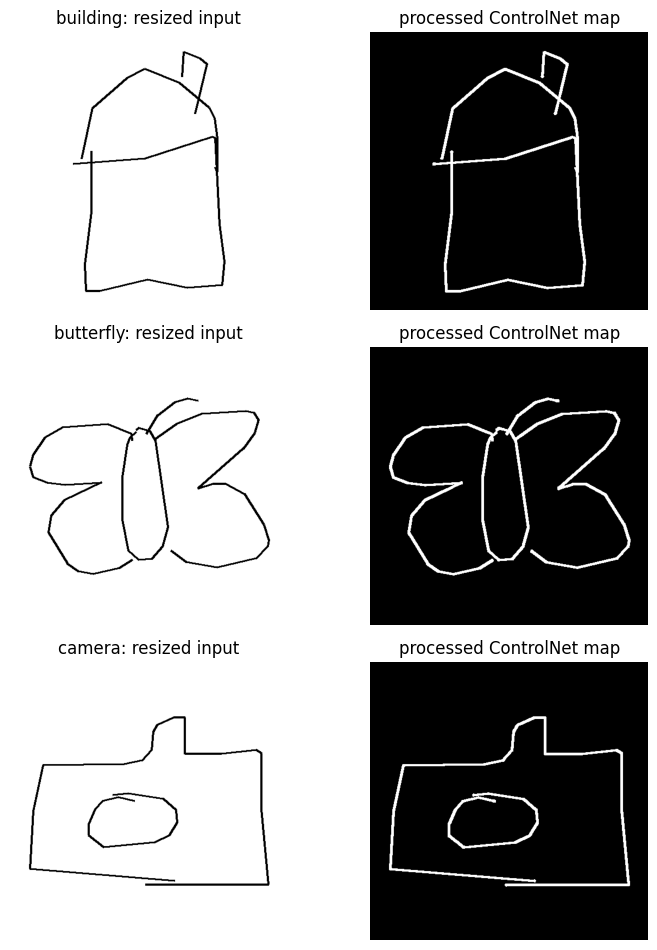

In [43]:
# Visual quality check: original grayscale input and processed ControlNet map.
if processed:
    names = list(processed)[:8]
    fig, axes = plt.subplots(len(names), 2, figsize=(8, 3.2*len(names)))
    if len(names) == 1: axes = np.array([axes])
    for i, name in enumerate(names):
        axes[i,0].imshow(processed[name]["original"], cmap="gray"); axes[i,0].set_title(f"{name}: resized input")
        axes[i,1].imshow(processed[name]["control"]); axes[i,1].set_title("processed ControlNet map")
        for ax in axes[i]: ax.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("Add sketches before continuing.")

## 4. Load Stable Diffusion 1.5 + ControlNet

The pipeline uses the Stable Diffusion 1.5 checkpoint with the matching scribble or line-art ControlNet and the UniPC scheduler. Half precision is enabled on CUDA to reduce memory use; CPU uses float32. The model weights are downloaded automatically from Hugging Face on first run; internet access is required.

The `local_dir_use_symlinks` message is a **deprecation warning, not a model-generation error**. It says a dependency called an older download option that Hugging Face now ignores. This notebook does not pass that option. If the model download completes and the next cell prints `Pipeline ready`, continue. If a traceback follows, troubleshoot the traceback rather than this warning.

In [44]:
BASE_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"
CONTROLNET_IDS = {
    "scribble": "lllyasviel/control_v11p_sd15_scribble",
    "lineart": "lllyasviel/control_v11p_sd15_lineart",
}
assert CONTROL_TYPE in CONTROLNET_IDS

# from_pretrained downloads model files to the standard HF cache; no deprecated
# local_dir_use_symlinks argument is passed.
controlnet = ControlNetModel.from_pretrained(CONTROLNET_IDS[CONTROL_TYPE], torch_dtype=DTYPE)
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    BASE_MODEL, controlnet=controlnet, torch_dtype=DTYPE,
    safety_checker=None, requires_safety_checker=False
)
pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)
pipe = pipe.to(DEVICE)
if DEVICE == "cuda":
    pipe.enable_attention_slicing()
    try: pipe.enable_vae_slicing()
    except Exception: pass
print("Pipeline ready:", BASE_MODEL, "+", CONTROLNET_IDS[CONTROL_TYPE])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Pipeline ready: stable-diffusion-v1-5/stable-diffusion-v1-5 + lllyasviel/control_v11p_sd15_scribble


In [45]:
def generate_image(control_image, prompt, steps=BASE_STEPS, guidance=BASE_GUIDANCE,
                   control_scale=BASE_CONTROL_SCALE, seed=SEED):
    generator = torch.Generator(device=DEVICE).manual_seed(int(seed))
    with torch.inference_mode():
        result = pipe(
            prompt=prompt, image=control_image.convert("RGB"),
            negative_prompt=NEGATIVE_PROMPT,
            num_inference_steps=int(steps), guidance_scale=float(guidance),
            controlnet_conditioning_scale=float(control_scale),
            generator=generator, height=IMAGE_SIZE, width=IMAGE_SIZE,
        )
    return result.images[0]

# Save exact configuration metadata with outputs.
RUN_CONFIG = {"base_model": BASE_MODEL, "controlnet": CONTROLNET_IDS[CONTROL_TYPE],
              "scheduler": "UniPCMultistepScheduler", "steps": BASE_STEPS,
              "guidance_scale": BASE_GUIDANCE, "controlnet_scale": BASE_CONTROL_SCALE,
              "seed": SEED, "image_size": IMAGE_SIZE, "device": DEVICE}
print(json.dumps(RUN_CONFIG, indent=2))

{
  "base_model": "stable-diffusion-v1-5/stable-diffusion-v1-5",
  "controlnet": "lllyasviel/control_v11p_sd15_scribble",
  "scheduler": "UniPCMultistepScheduler",
  "steps": 28,
  "guidance_scale": 7.0,
  "controlnet_scale": 1.0,
  "seed": 42,
  "image_size": 512,
  "device": "cuda"
}


## 5. Baseline generation

Every available sketch is processed with the same baseline settings. Outputs are saved as PNG files, and the exact prompt/settings are stored as JSON sidecars.

In [46]:
baseline_rows = []
for name, item in processed.items():
    out_path = ROOT / "outputs/baseline" / f"{name}.png"
    image = generate_image(item["control"], item["prompt"])
    image.save(out_path)
    metadata = {**RUN_CONFIG, "sketch": name, "prompt": item["prompt"]}
    (out_path.with_suffix(".json")).write_text(json.dumps(metadata, indent=2))
    baseline_rows.append({"sketch": name, "prompt": item["prompt"], "output": str(out_path)})
    print("Generated:", name, "→", out_path)
print("Baseline images generated:", len(baseline_rows))

  0%|          | 0/28 [00:00<?, ?it/s]

Generated: building → /kaggle/working/sketch2image/outputs/baseline/building.png


  0%|          | 0/28 [00:00<?, ?it/s]

Generated: butterfly → /kaggle/working/sketch2image/outputs/baseline/butterfly.png


  0%|          | 0/28 [00:00<?, ?it/s]

Generated: camera → /kaggle/working/sketch2image/outputs/baseline/camera.png
Baseline images generated: 3


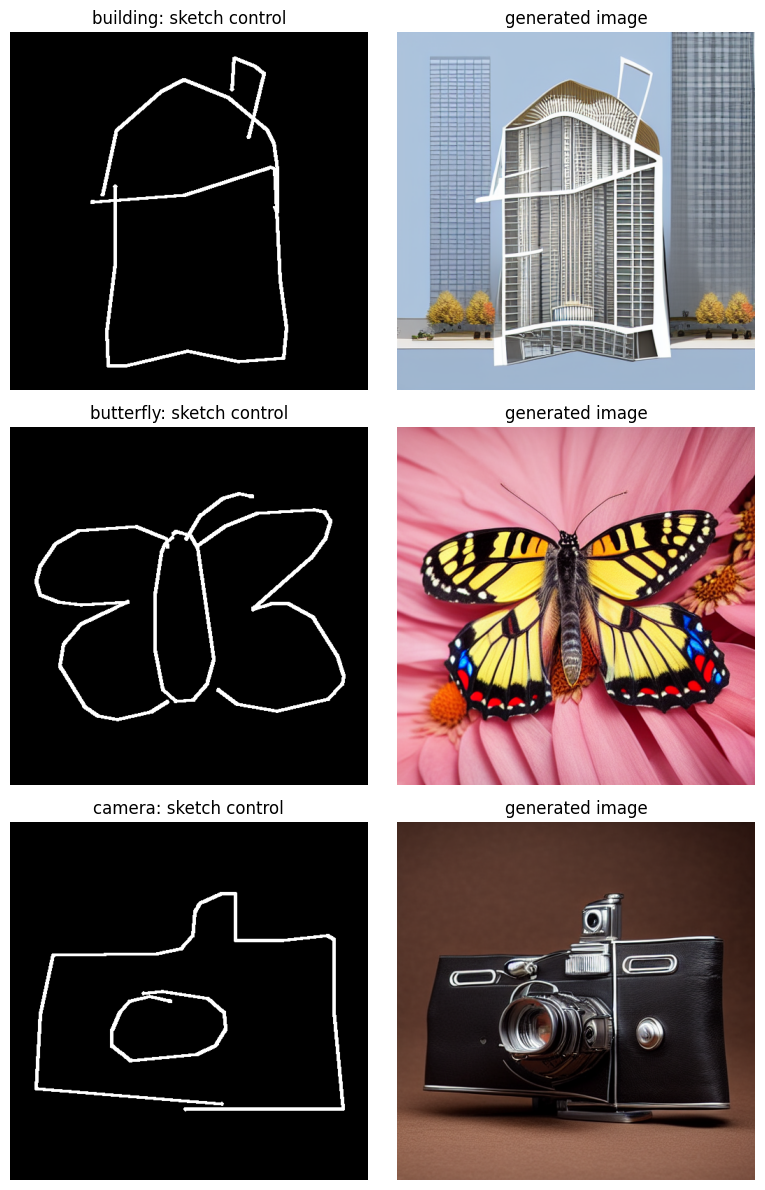

In [47]:
# Baseline visual comparison
if baseline_rows:
    names = [r["sketch"] for r in baseline_rows]
    n = len(names)
    fig, axes = plt.subplots(n, 2, figsize=(8, 4*n))
    if n == 1: axes = np.array([axes])
    for i, name in enumerate(names):
        axes[i,0].imshow(processed[name]["control"]); axes[i,0].set_title(f"{name}: sketch control")
        axes[i,1].imshow(Image.open(ROOT / "outputs/baseline" / f"{name}.png")); axes[i,1].set_title("generated image")
        for ax in axes[i]: ax.axis("off")
    plt.tight_layout(); plt.savefig(ROOT / "outputs/baseline_overview.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Parameter experiments

Two controlled sweeps vary one parameter at a time while holding the sketch, prompt, and random seed constant:

- **ControlNet conditioning scale:** 0.5, 0.8, 1.0, 1.2, 1.5.
- **Text guidance scale:** 3.5, 5.0, 7.0, 9.0, 11.0.

To manage GPU time, experiments run on up to three sketches by default. Set `EXPERIMENT_SKETCHES` to a subset of available names, or `None` to use the first three.

In [48]:
EXPERIMENT_SKETCHES = list(processed)[:3]  # set to None to select first three automatically
if EXPERIMENT_SKETCHES is None: EXPERIMENT_SKETCHES = list(processed)[:3]
CONTROL_SCALES = [0.5, 0.8, 1.0, 1.2, 1.5]
GUIDANCE_SCALES = [3.5, 5.0, 7.0, 9.0, 11.0]
experiment_rows = []

for name in EXPERIMENT_SKETCHES:
    if name not in processed: continue
    item = processed[name]
    for value in CONTROL_SCALES:
        img = generate_image(item["control"], item["prompt"], control_scale=value, seed=SEED)
        img.save(ROOT / "outputs/experiments" / f"{name}_control_{value:.1f}.png")
        experiment_rows.append({"sketch": name, "experiment": "controlnet_scale", "value": value,
                                "image": f"outputs/experiments/{name}_control_{value:.1f}.png"})
    for value in GUIDANCE_SCALES:
        img = generate_image(item["control"], item["prompt"], guidance=value, seed=SEED)
        img.save(ROOT / "outputs/experiments" / f"{name}_guidance_{value:.1f}.png")
        experiment_rows.append({"sketch": name, "experiment": "guidance_scale", "value": value,
                                "image": f"outputs/experiments/{name}_guidance_{value:.1f}.png"})
experiments_df = pd.DataFrame(experiment_rows)
experiments_df.to_csv(ROOT / "outputs/experiment_runs.csv", index=False)
print("Saved experiment generations:", len(experiments_df))

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

... (21 outputs left out)

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

Saved experiment generations: 30


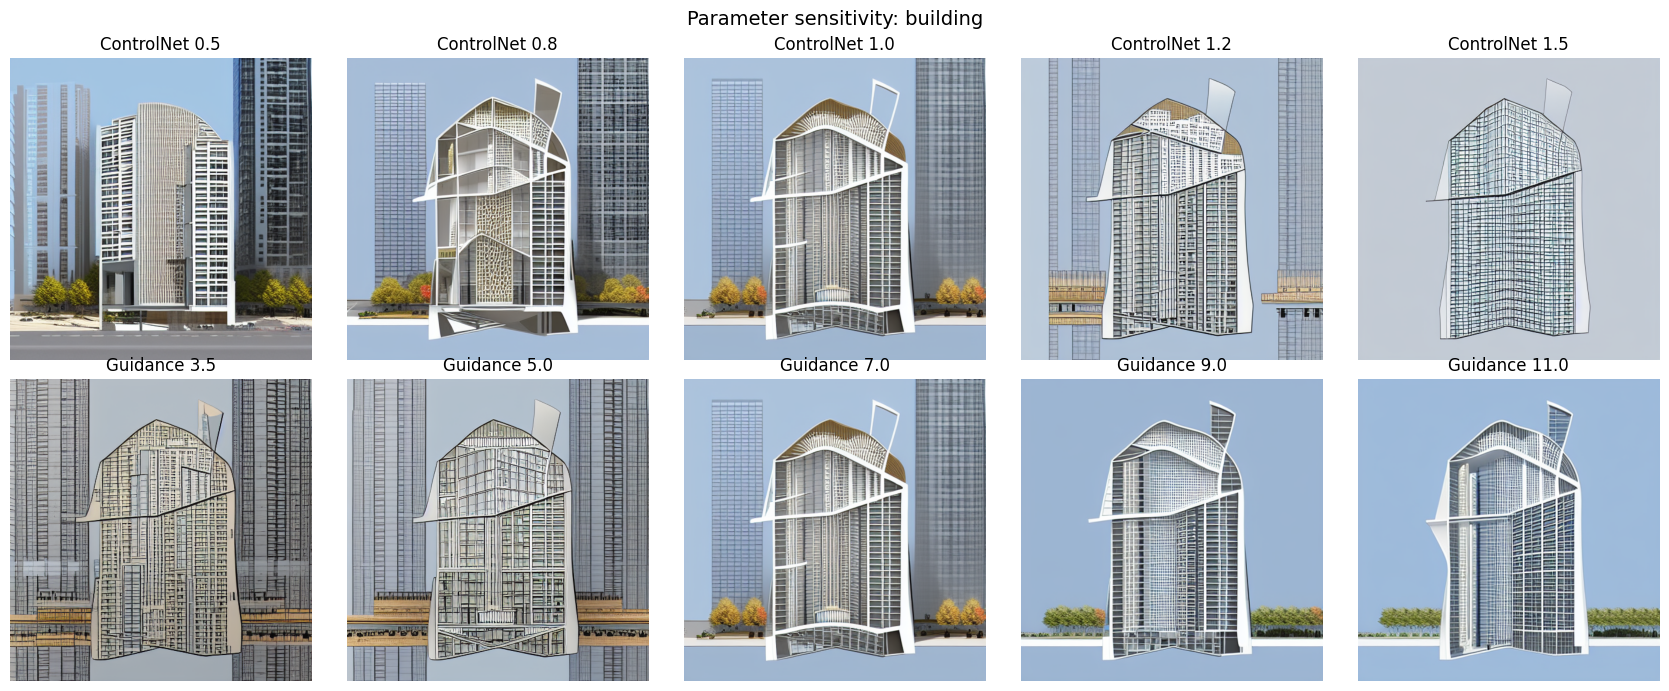

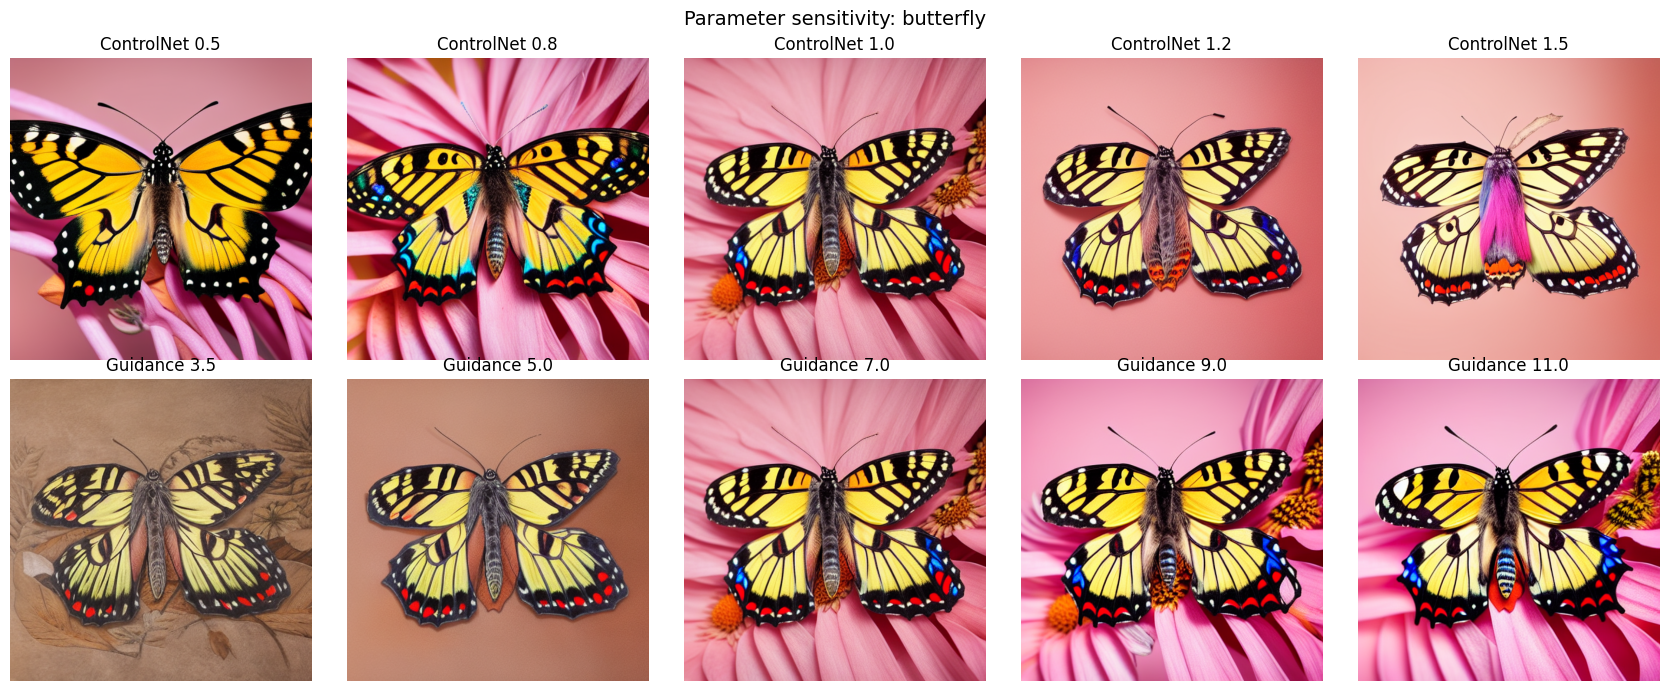

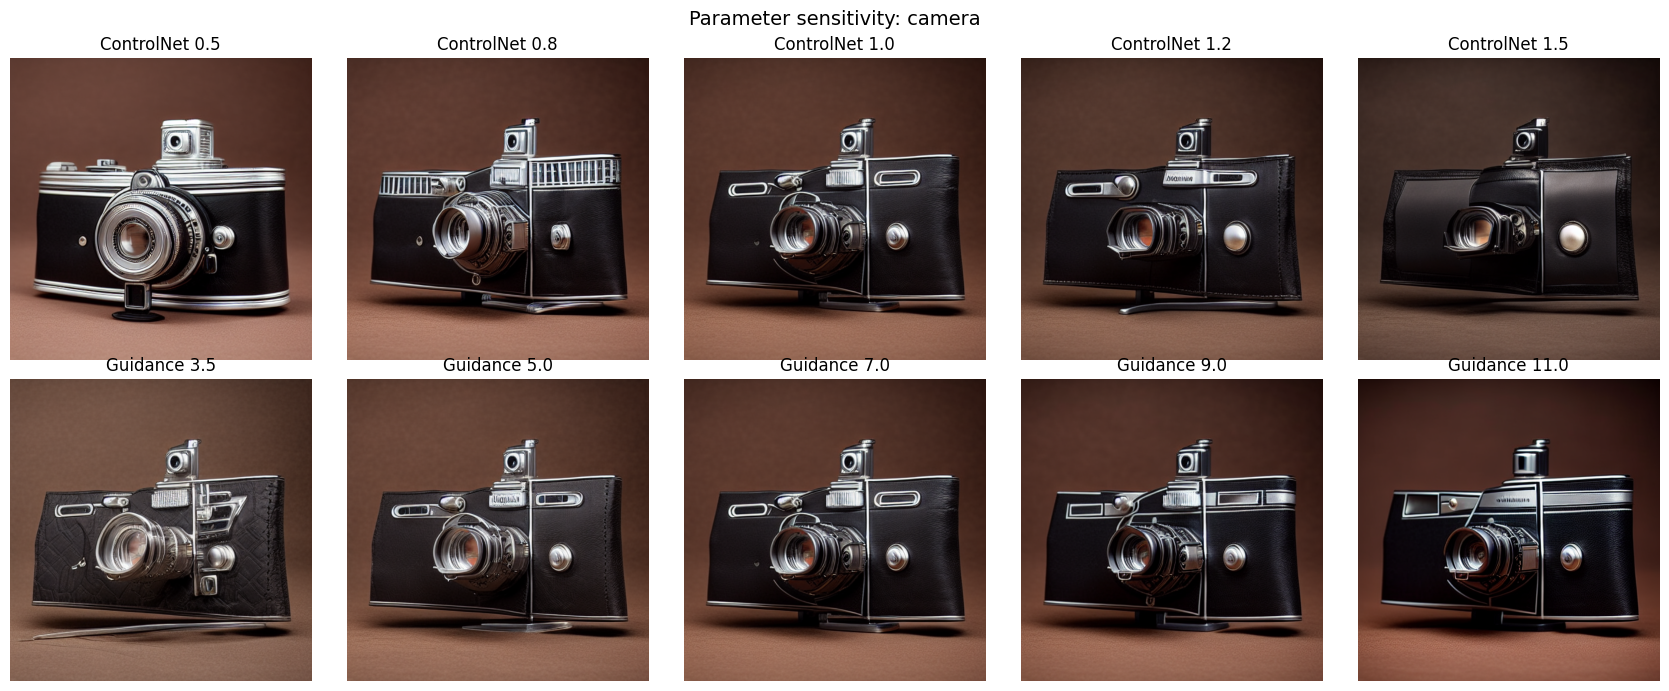

In [49]:
# Display experiment grids for each selected sketch.
for name in EXPERIMENT_SKETCHES:
    if name not in processed: continue
    fig, axes = plt.subplots(2, 5, figsize=(17, 7))
    for j, value in enumerate(CONTROL_SCALES):
        p = ROOT / "outputs/experiments" / f"{name}_control_{value:.1f}.png"
        axes[0,j].imshow(Image.open(p)); axes[0,j].set_title(f"ControlNet {value}"); axes[0,j].axis("off")
    for j, value in enumerate(GUIDANCE_SCALES):
        p = ROOT / "outputs/experiments" / f"{name}_guidance_{value:.1f}.png"
        axes[1,j].imshow(Image.open(p)); axes[1,j].set_title(f"Guidance {value}"); axes[1,j].axis("off")
    fig.suptitle(f"Parameter sensitivity: {name}", fontsize=14)
    plt.tight_layout(); plt.savefig(ROOT / "outputs/experiments" / f"{name}_parameter_grid.png", dpi=140); plt.show()

## 7. Quantitative sketch-preservation evaluation

We compare the skeletonized white strokes in the processed sketch with Canny edges in the generated image. **Edge recall** is the fraction of sketch-line pixels with a generated edge within a tolerance radius (5 px). **Chamfer distance** is the mean distance from sketch-line pixels to the nearest generated edge (lower is closer).

These are approximate structural-alignment indicators, not a complete measure of image quality or semantic correctness. They can be affected by texture, object boundaries, and the amount of detail in the generated image.

In [50]:
def preservation_scores(control, generated, tolerance=5):
    control_arr = np.asarray(control.convert("L")) > 127
    lines = skeletonize(control_arr)
    gray = cv2.cvtColor(np.asarray(generated.convert("RGB")), cv2.COLOR_RGB2GRAY)
    gray = cv2.GaussianBlur(gray, (5,5), 0)
    edges = cv2.Canny(gray, 50, 150) > 0
    if not edges.any() or not lines.any():
        return {"edge_recall": 0.0, "chamfer_px": float("nan")}
    dist = cv2.distanceTransform((~edges).astype(np.uint8), cv2.DIST_L2, 3)
    d = dist[lines]
    return {"edge_recall": float((d <= tolerance).mean()), "chamfer_px": float(d.mean())}

metric_rows = []
for name, item in processed.items():
    image = Image.open(ROOT / "outputs/baseline" / f"{name}.png").convert("RGB")
    scores = preservation_scores(item["control"], image)
    metric_rows.append({"sketch": name, **scores})
metrics_df = pd.DataFrame(metric_rows)
metrics_df.to_csv(ROOT / "outputs/metrics_baseline.csv", index=False)
display(metrics_df.round(4))
print("Mean metrics (actual run):")
display(metrics_df[["edge_recall", "chamfer_px"]].mean().to_frame("mean").round(4))

,sketch,edge_recall,chamfer_px
0,building,0.9880,1.0064
1,butterfly,0.9658,1.4080
2,camera,0.9137,2.1683


Mean metrics (actual run):


,mean
edge_recall,0.9558
chamfer_px,1.5275


,sketch,controlnet_scale,edge_recall,chamfer_px
0,building,0.5,0.6656,6.1526
1,building,0.8,0.9943,1.4241
2,building,1.0,0.9880,1.0064
3,building,1.2,1.0000,0.7288
4,building,1.5,1.0000,0.7094
5,butterfly,0.5,0.7265,3.5838
6,butterfly,0.8,0.8643,2.5953
7,butterfly,1.0,0.9658,1.4080
8,butterfly,1.2,0.9920,1.1105
9,butterfly,1.5,0.9940,0.8520


,controlnet_scale,edge_recall,chamfer_px
0,0.5,0.7706,4.0840
1,0.8,0.9416,1.9539
2,1.0,0.9558,1.5275
3,1.2,0.9811,1.0893
4,1.5,0.9619,1.1800


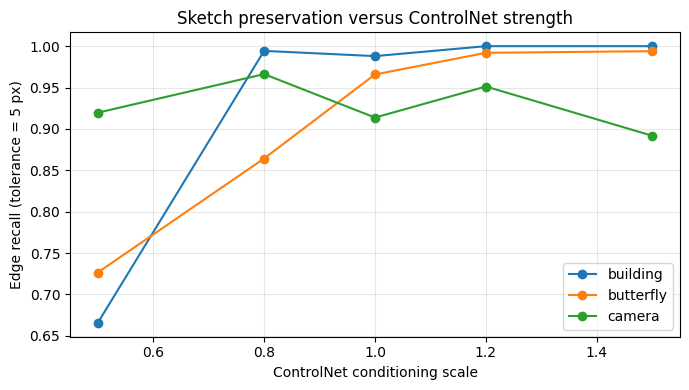

In [51]:
# Evaluate how ControlNet strength changes structural alignment.
scale_metric_rows = []
for name in EXPERIMENT_SKETCHES:
    if name not in processed: continue
    control = processed[name]["control"]
    for scale in CONTROL_SCALES:
        path = ROOT / "outputs/experiments" / f"{name}_control_{scale:.1f}.png"
        scores = preservation_scores(control, Image.open(path).convert("RGB"))
        scale_metric_rows.append({"sketch": name, "controlnet_scale": scale, **scores})
scale_metrics_df = pd.DataFrame(scale_metric_rows)
scale_metrics_df.to_csv(ROOT / "outputs/metrics_controlnet_scale.csv", index=False)
display(scale_metrics_df.round(4))

if not scale_metrics_df.empty:
    summary = scale_metrics_df.groupby("controlnet_scale")[["edge_recall", "chamfer_px"]].mean().reset_index()
    display(summary.round(4))
    fig, ax = plt.subplots(figsize=(7,4))
    for name, part in scale_metrics_df.groupby("sketch"):
        ax.plot(part["controlnet_scale"], part["edge_recall"], marker="o", label=name)
    ax.set(xlabel="ControlNet conditioning scale", ylabel="Edge recall (tolerance = 5 px)",
           title="Sketch preservation versus ControlNet strength")
    ax.grid(alpha=.3); ax.legend(); plt.tight_layout()
    plt.savefig(ROOT / "outputs/metrics_controlnet_scale.png", dpi=150); plt.show()

## 8. Results interpretation and limitations

The cells below summarize the metrics calculated from your run. Interpret higher edge recall and lower Chamfer distance as stronger approximate alignment with the sketch, while visually checking that the prompt content and image quality remain satisfactory. Do not select a setting using a single metric alone.

Limitations: the evaluation uses edge proximity rather than human ratings; the sample size is the number of sketches available; results depend on prompts, preprocessing, random seed, and model versions. Stable Diffusion inference is stochastic, so fixed seeds improve reproducibility but do not guarantee identical results across hardware/software versions.

**Download warning note:** Hugging Face may print a `local_dir_use_symlinks` deprecation warning from a dependency. It only says the argument is ignored by newer Hub versions; it does not indicate a failed model download. If the model download completes and the pipeline prints `Pipeline ready`, you can continue.

In [52]:
if len(metrics_df):
    print(f"Baseline evaluated on {len(metrics_df)} sketch(es).")
    print(f"Mean edge recall: {metrics_df.edge_recall.mean():.4f}")
    print(f"Mean Chamfer distance (px): {metrics_df.chamfer_px.mean():.4f}")
else:
    print("No baseline metrics available; run baseline generation first.")
if len(scale_metrics_df):
    print("\nMean scores by ControlNet scale:")
    display(scale_metrics_df.groupby("controlnet_scale")[["edge_recall", "chamfer_px"]].mean().round(4))

Baseline evaluated on 3 sketch(es).
Mean edge recall: 0.9558
Mean Chamfer distance (px): 1.5275

Mean scores by ControlNet scale:


,edge_recall,chamfer_px
controlnet_scale,,
0.5,0.7706,4.0840
0.8,0.9416,1.9539
1.0,0.9558,1.5275
1.2,0.9811,1.0893
1.5,0.9619,1.1800


## 9. Export artifacts

This cell writes a run manifest and creates a ZIP containing generated images, experiment grids, and CSV metrics. It deliberately does not push anything to GitHub or request/store access tokens.

In [53]:
manifest = {**RUN_CONFIG,
            "prompts": {k: v["prompt"] for k, v in processed.items()},
            "input_sketches": [Path(v["path"]).name for v in processed.values()],
            "experiment_sketches": EXPERIMENT_SKETCHES,
            "control_scales": CONTROL_SCALES,
            "guidance_scales": GUIDANCE_SCALES,
            "baseline_metrics_mean": metrics_df[["edge_recall", "chamfer_px"]].mean().to_dict() if len(metrics_df) else {},
            "image_sources": str(ROOT / "sketches/source_attribution.csv") if (ROOT / "sketches/source_attribution.csv").exists() else "User-provided/local images; see input_sketches"}
(ROOT / "outputs/run_manifest.json").write_text(json.dumps(manifest, indent=2))
import zipfile
zip_path = ROOT / "sketch2image_results.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for folder in [ROOT / "outputs", ROOT / "sketches"]:
        for file in folder.rglob("*"):
            if file.is_file(): zf.write(file, file.relative_to(ROOT))
print("Results archive:", zip_path)
print("Outputs folder:", ROOT / "outputs")

Results archive: /kaggle/working/sketch2image/sketch2image_results.zip
Outputs folder: /kaggle/working/sketch2image/outputs


## 10. Optional: launch the Gradio demo

Run this only after the main pipeline is loaded. Set `share=False` for a local/private session.

In [57]:
# interactive demo (requires Gradio)
import gradio as gr

def demo_generate(sketch_image, prompt, control_strength, guidance, steps, seed):
    if sketch_image is None: raise gr.Error("Please upload a sketch first.")
    gray = ImageOps.grayscale(sketch_image)
    control = clean_sketch(load_sketch_from_pil(gray))
    result = generate_image(control, prompt, steps=steps, guidance=guidance,
                            control_scale=control_strength, seed=seed)
    return control, result

def load_sketch_from_pil(img):
    w,h = img.size; scale = IMAGE_SIZE/max(w,h)
    nw=max(8,int(round(w*scale/8)*8)); nh=max(8,int(round(h*scale/8)*8))
    resized=img.resize((nw,nh),Image.Resampling.LANCZOS)
    canvas=Image.new("L",(IMAGE_SIZE,IMAGE_SIZE),255); canvas.paste(resized,((IMAGE_SIZE-nw)//2,(IMAGE_SIZE-nh)//2))
    return canvas

with gr.Blocks(title="Sketch to Image with ControlNet") as demo:
    gr.Markdown("# Sketch-to-Image Generation — Upload a sketch and describe the desired image.")
    with gr.Row():
        sketch_in = gr.Image(type="pil", label="Input sketch")
        with gr.Column():
            prompt_in = gr.Textbox(label="Prompt", value="a detailed photorealistic scene, natural lighting")
            strength = gr.Slider(0, 1.8, value=1.0, step=.1, label="ControlNet strength")
            guidance_in = gr.Slider(1, 15, value=7.0, step=.5, label="Guidance scale")
            steps_in = gr.Slider(10, 50, value=28, step=1, label="Inference steps")
            seed_in = gr.Number(value=42, precision=0, label="Seed")
            run_btn = gr.Button("Generate")
    control_out = gr.Image(label="Processed sketch")
    image_out = gr.Image(label="Generated image")
    run_btn.click(demo_generate, [sketch_in,prompt_in,strength,guidance_in,steps_in,seed_in], [control_out,image_out])
# Uncomment to launch:
# demo.launch(share=False, debug=True)

IndentationError: unindent does not match any outer indentation level (<tokenize>, line 34)